# Preprocess DEAP

In [1]:
# imports
import mne
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# data & processing
raw = mne.io.read_raw_bdf('data/DEAP/EEG_RAW/s09.bdf', preload=True)
events = mne.find_events(raw, stim_channel='Status', shortest_event=1, initial_event=True)

Extracting EDF parameters from /Users/yeganeh/Codes/EEGModalNet/data/DEAP/EEG_RAW/s09.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1928703  =      0.000 ...  3766.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]


In [3]:
channels = ['O1', 'O2', 'P3', 'P4', 'C3', 'C4', 'F3', 'F4']

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


/var/folders/6s/d689xnpd4553fw2yp02b3gv40000gn/T/ipykernel_77561/1589456404.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw.pick(channels).plot_psd(fmin=0, fmax=64, show=False)


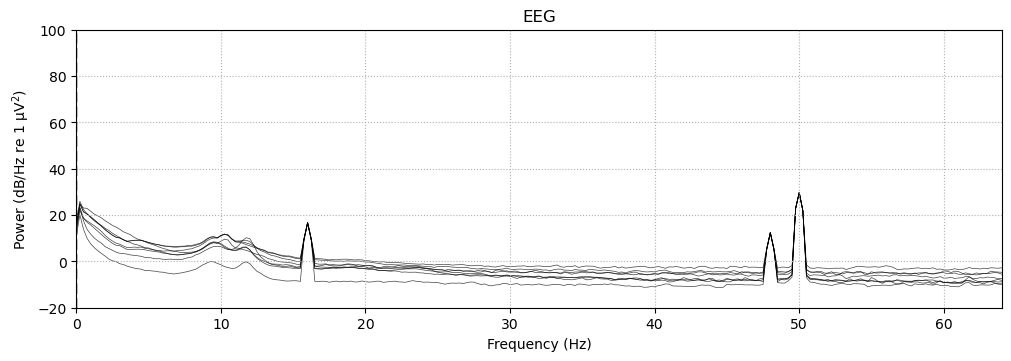

In [4]:
raw.pick(channels).plot_psd(fmin=0, fmax=64, show=False)
plt.ylim([-20, 100])
plt.show()

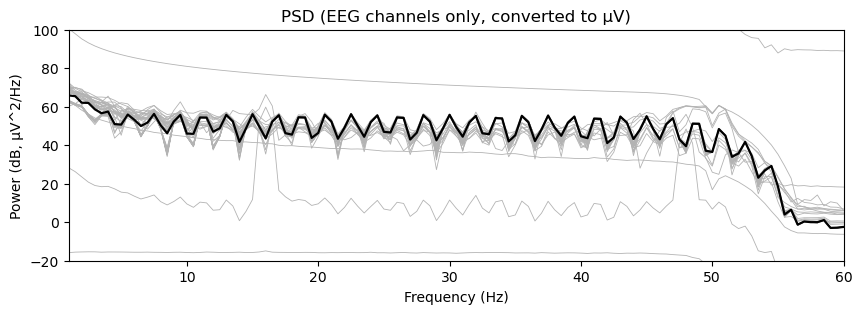

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA, create_eog_epochs

# 1) check min/max to spot huge channels or flat ones
data = raw.get_data()
mins, maxs = data.min(axis=1), data.max(axis=1)
for name, mn, mx in zip(raw.ch_names, mins, maxs):
    if np.abs(mn) > 1.0 or np.abs(mx) > 1.0:  # >1 V (!) suspicious
        print("Large amplitude channel:", name, mn, mx)
    if np.abs(mx - mn) < 1e-8:
        print("Flat channel:", name)

# 2) pick only EEG channels (drop peripheral channels like GSR, Resp, Temp, EMG)
picks_eeg = mne.pick_types(raw.info, eeg=True, eog=False, stim=False, misc=False)
raw_eeg = raw.copy().pick(picks_eeg)
print("Using EEG channels:", [raw_eeg.ch_names[i] for i in range(len(raw_eeg.ch_names))])

# 3) convert to microvolts for plotting dB(µV^2/Hz)
raw_eeg.apply_function(lambda x: x * 1e6)
# raw_eeg.set_units({ch: 'µV' for ch in raw_eeg.ch_names})
  # careful: modifies data in-place; units now µV

# # 4) set montage (optional) to get realistic topographies; fallback to standard_1020
# try:
#     montage = mne.channels.make_standard_montage('standard_1020')
#     raw_eeg.set_montage(montage, match_case=False, on_missing='ignore')
# except Exception:
#     pass

# 5) notch and bandpass (typical DEAP-style is 4-45 Hz; you can use 1-45 Hz depending on goals)
raw_eeg.notch_filter(freqs=[50, 100], verbose=False)  # remove mains
raw_eeg.filter(l_freq=1.0, h_freq=45.0, fir_design='firwin', verbose=False)

# 6) detect bad channels (simple threshold or use autoreject)
# simple variance test:
chan_var = np.var(raw_eeg.get_data(), axis=1)
z = (chan_var - chan_var.mean()) / chan_var.std()
bad_idx = np.where(z > 3)[0]
if len(bad_idx) > 0:
    bads = [raw_eeg.ch_names[i] for i in bad_idx]
    print("Marked bad channels:", bads)
    raw_eeg.info['bads'].extend(bads)

# # 7) optional: run ICA to remove large EOG artifacts (if EOG channels present)
# # (skip if you don't want to run heavy ICA)
# try:
#     ica = ICA(n_components=15, random_state=97, max_iter='auto')
#     ica.fit(raw_eeg)
#     # find eog components (if eog channels exist)
#     eog_chs = mne.pick_types(raw.info, eog=True)
#     if len(eog_chs) > 0:
#         eog_inds, scores = ica.find_bads_eog(raw, ch_name=None)
#         ica.exclude = eog_inds
#     raw_eeg = ica.apply(raw_eeg.copy())
# except Exception as e:
#     print("ICA skipped/failed:", e)

# 8) compute PSD with Welch (nice units since we converted to µV)
x = raw_eeg.get_data()
psds, freqs = mne.time_frequency.psd_array_welch(
    x, sfreq=512, fmin=1.0, fmax=60.0, n_fft=int(raw_eeg.info['sfreq']*2),
    n_overlap=0, verbose=False
)

# convert to dB: 10*log10(µV^2/Hz)
psds_db = 10 * np.log10(psds)

# 9) plot median PSD and some channel lines
import matplotlib.pyplot as plt
plt.figure(figsize=(10,3))
plt.plot(freqs, psds_db.T, color='0.7', linewidth=0.6)   # many channel lines
plt.plot(freqs, np.median(psds_db, axis=0), color='k', linewidth=1.6)  # median
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB, µV^2/Hz)")
plt.xlim(1,60)
plt.ylim(-20, 100)
plt.title("PSD (EEG channels only, converted to µV)")
plt.show()


NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


/var/folders/6s/d689xnpd4553fw2yp02b3gv40000gn/T/ipykernel_75951/3949885159.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  eeg.pick(channels).plot_psd(fmin=1, fmax=60, show=False)


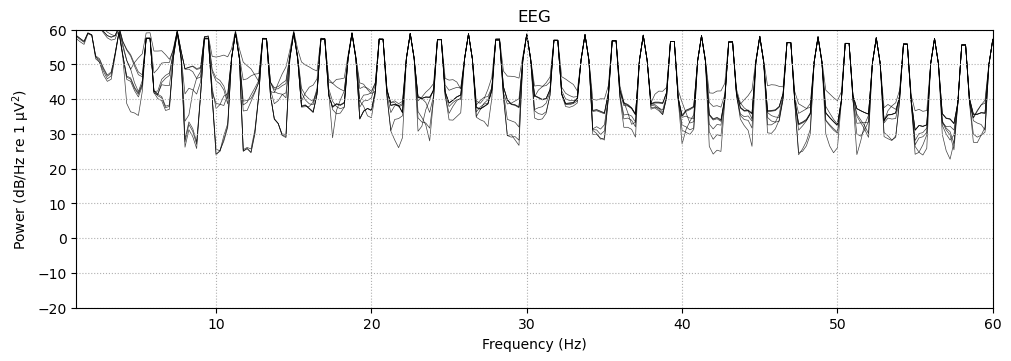

In [17]:
eeg.pick(channels).plot_psd(fmin=1, fmax=60, show=False)
plt.ylim([-20, 60])
plt.show()

### Decode event ids & Segment

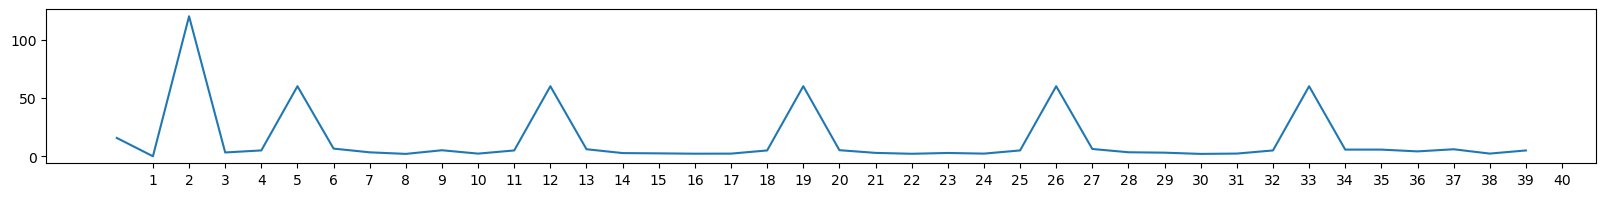

In [7]:
# Convert sample numbers to seconds
event_times = events[:, 0] / eeg.info['sfreq']
diff_arr = np.diff(event_times)
event_id_occurance = np.unique(events[:, 2], return_counts=True)
plt.figure(figsize=(20, 2))
l = 40
plt.plot(diff_arr[:l])
plt.xticks(np.arange(1, l+1))
plt.show()

In [ ]:
# the number of occurance of each trigger id and the interval between them tell us what each corresponds to:
event_id = {'baseline_start': 3,
            'video_start': 4,
            'video_end': 5}

# epoch and baseline correct
epochs = mne.Epochs(eeg,
                    events,
                    event_id=event_id['video_start'],  # only need the video start point to epoch the data
                    tmin=-5,
                    tmax=60,
                    baseline=(-5, 0))

Not setting metadata
40 matching events found
No baseline correction applied
0 projection items activated


## Create a Xarray dataset of all participants

In [10]:
preprocess = True
highpass = True
remove_line_noise = True
resample = True
channels = ['O1', 'O2', 'P3', 'P4', 'C3', 'C4', 'F3', 'F4']

In [ ]:
# pick channels
epochs.load_data()
epochs.pick(channels)
epochs.resample(128)

In [14]:
x = epochs.get_data()
x.shape

(40, 8, 7680)

In [ ]:


from src.EEGModalNet.preprocessing.preprocessing import preprocess_data

if resample:
    epochs.resample(128)

x = epochs.get_data() # the dimension of x should be (features, time)

if preprocess:
    x = preprocess_data(x, baseline_duration=None, sampling_rate=128)

if highpass:
    sos = butter(4, 0.5, btype='high', fs=128, output='sos')
    x = sosfiltfilt(sos, x, axis=-1)

if remove_line_noise:
    x, _ = dss.dss_line(x.T, fline=50, sfreq=128, nremove=1)
    x = x.T


# downsample
# preprocess
# highpass
# remove line noise